# 04 · The hedonic benchmarks (paper Tables 6–7)

> **Paper** &nbsp; I-Cheng Yeh and Tzu-Kuang Hsu (2018), "Building real estate
> valuation models with comparative approach through case-based reasoning",
> *Applied Soft Computing* **65**, 260-271.
> [doi:10.1016/j.asoc.2018.01.029](https://doi.org/10.1016/j.asoc.2018.01.029)
>
> **Data** &nbsp; UCI Machine Learning Repository, *Real Estate Valuation*
> ([doi:10.24432/C5J30W](https://doi.org/10.24432/C5J30W)), CC BY 4.0 — the
> Sindian circle of supply and demand, 414 transactions.

---

Section 5.3 compares the approach against two classical hedonic price models on the same split:

* **Multivariate regression** — Eq. (36), OLS on the four factors plus northing, easting, their squares and their interaction.
* **Neural network** — a multi-layer perceptron, tuned by the authors to one hidden layer of five units, learning rate 0.6, 1500 learning cycles.

The MLP is written out in NumPy rather than taken from a library, so that the published hyper-parameters mean what they meant in the paper.

In [1]:
import sys, warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qca import config, data, experiments, importance, metrics, plots
from qca.decomposition import StepwiseDecomposition
from qca.estimator import QuantitativeComparativeApproach
from qca.benchmarks import MultivariateRegression, PaperMLP

plots.use_paper_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
df = data.load()
train, test = data.train_test_split_paper(df, config.RANDOM_STATE)
mean_price = float(df[config.TARGET].mean())
y_test = test[config.TARGET]

## 1. Multivariate regression (Eq. 36)

$$Y = a_0 + a_1x_1 + a_2x_2 + a_3x_3 + a_4x_4 + a_5N + a_6E + a_7N^2 + a_8E^2 + a_9NE$$

In [3]:
mra = MultivariateRegression().fit(train)
mra_pred = mra.predict(test)
mra.summary().to_frame().round(6)

,coefficient
intercept,"-10,970.6981"
date,5.4733
age,-0.2701
mrt,-0.0104
stores,0.4759
N,0.0024
E,-0.0000
N^2,0.0000
E^2,0.0000
N*E,0.0000


The signs are the expected ones: negative on MRT distance and house age, positive on convenience stores and the transaction date. The quadratic coordinate terms are the model's only way to bend to location, and they are what the paper's Eq. (25) surface does more directly.

## 2. The neural network

One detail decides whether this benchmark is fair. A **learning cycle** in the back-propagation literature the paper follows is one pass of *pattern-by-pattern* updates, not one batch-averaged step. Implemented as batch updates, 1500 cycles at learning rate 0.6 leaves the network far short of convergence and the benchmark looks far worse than the paper's — about RMSE 10.9 instead of 7.1. Implemented per pattern, it reproduces.

training RMSE after 1500 cycles: 7.744
test RMSE: 7.125


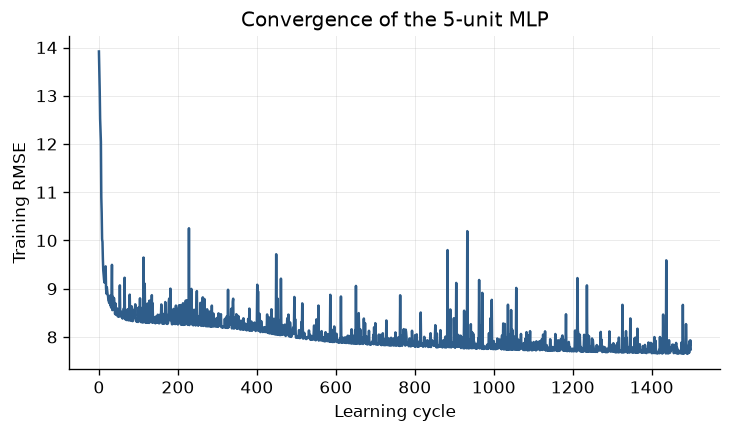

In [4]:
ann = PaperMLP(random_state=0).fit(train)
ann_pred = ann.predict(test)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(ann.history_, color=plots.PALETTE[0])
ax.set_xlabel("Learning cycle")
ax.set_ylabel("Training RMSE")
ax.set_title("Convergence of the 5-unit MLP")
print(f"training RMSE after {ann.n_cycles} cycles: {ann.history_[-1]:.3f}")
print(f"test RMSE: {metrics.rmse(y_test, ann_pred):.3f}")

### Is five hidden units the right choice?

The paper reports it as the best of a number of trials without showing them. Re-running the search on the training set:

In [5]:
rows = []
for units in [2, 3, 5, 8, 12]:
    net = PaperMLP(hidden_units=units, random_state=0).fit(train)
    rows.append({
        "hidden units": units,
        "training RMSE": net.history_[-1],
        "test RMSE": metrics.rmse(y_test, net.predict(test)),
    })
pd.DataFrame(rows).set_index("hidden units").round(4)

,training RMSE,test RMSE
hidden units,,
2,7.8394,7.4166
3,7.9290,7.4338
5,7.7438,7.1255
8,7.6696,7.1365
12,7.8108,7.4367


## 3. The three approaches side by side (paper Tables 5–7)

In [6]:
grid_table = experiments.radius_grid(train, test)
method, radius = experiments.best_setting(grid_table)
preds = experiments.fit_all_models(train, test, method, radius,
                                   include_modern=False)
comparison = experiments.evaluation_table(test, preds, mean_price)
comparison.round(4)

,20% error hit rate,10% error hit rate,R2 (1-SSE/SST),R2 (corr^2),RMSE,MAE,MAPE,Avg. house price,RMSE/Avg. house price
Quantitative Comparative Approach,76.0870,53.6232,0.6818,0.6916,7.3010,4.9129,16.6957,37.9802,0.1922
Multivariate regression analysis,75.3623,48.5507,0.6414,0.6492,7.7510,5.2472,17.8792,37.9802,0.2041
Neural network (paper spec),81.1594,50.0000,0.6969,0.6971,7.1255,4.7983,15.9253,37.9802,0.1876


In [7]:
paper = pd.DataFrame(
    [[80.2, 52.9, 0.683, 7.73, 0.204],
     [74.3, 41.8, 0.530, 8.65, 0.228],
     [78.0, 48.8, 0.627, 8.06, 0.212]],
    index=comparison.index,
    columns=["20% error hit rate", "10% error hit rate", "R2",
             "RMSE", "RMSE/Avg. house price"],
)
print("as printed in the paper:")
paper

as printed in the paper:


,20% error hit rate,10% error hit rate,R2,RMSE,RMSE/Avg. house price
Quantitative Comparative Approach,80.2000,52.9000,0.6830,7.7300,0.2040
Multivariate regression analysis,74.3000,41.8000,0.5300,8.6500,0.2280
Neural network (paper spec),78.0000,48.8000,0.6270,8.0600,0.2120


In [8]:
side = pd.DataFrame({
    "RMSE — replication": comparison["RMSE"],
    "RMSE — paper": paper["RMSE"],
    "rank — replication": comparison["RMSE"].rank().astype(int),
    "rank — paper": paper["RMSE"].rank().astype(int),
})
side.round(3)

,RMSE — replication,RMSE — paper,rank — replication,rank — paper
Quantitative Comparative Approach,7.3010,7.7300,2,1
Multivariate regression analysis,7.7510,8.6500,3,3
Neural network (paper spec),7.1250,8.0600,1,2


**Half of the paper's finding (3) replicates on this split, and half does not.**

*Replicates.* The Quantitative Comparative Approach beats multivariate regression, on RMSE and on both hit rates. This is the larger of the two gaps the paper reports, and it survives.

*Does not replicate.* The neural network is **not** worse than the QCA here — on RMSE it is marginally better, reversing the paper's ordering of the two. The margin is small in both directions: the paper has the QCA ahead by 0.33 RMSE, this split has the network ahead by about 0.18.

Neither number deserves to be read as a ranking. A gap of 0.2 RMSE on 138 test cases drawn from one random split is not evidence of anything, and that applies to the paper's result as much as to this one. Notebook 05 settles it properly by repeating the whole comparison over 30 independent splits and testing the differences in pairs — where the QCA's advantage over regression holds up and its difference from the network does not.

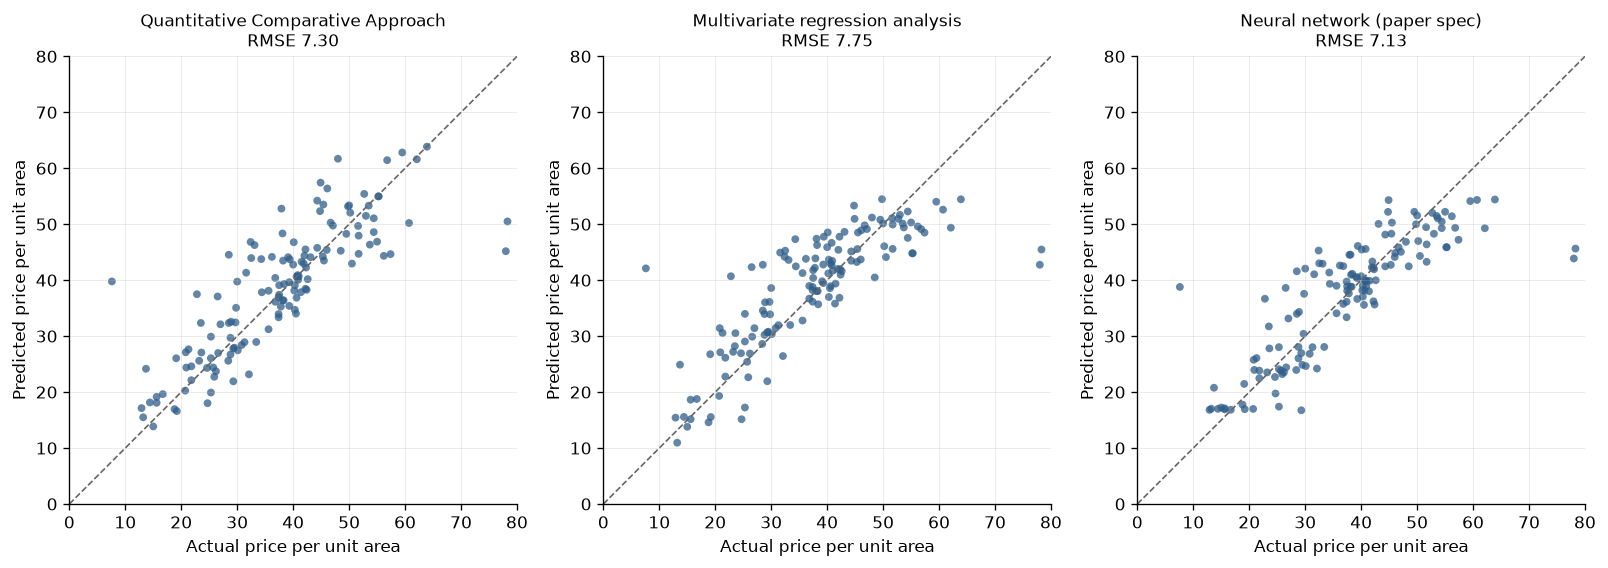

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5))
lim = float(max(y_test.max(), 80))
for ax, (name, pred) in zip(axes, preds.items()):
    plots.actual_vs_predicted(
        y_test, pred, ax=ax, lim=lim,
        title=f"{name}\nRMSE {metrics.rmse(y_test, pred):.2f}",
    )
fig.tight_layout()

## 4. Where the models disagree

All three share the same errors on the same handful of properties, which says the residual is in the data rather than in any one model.

In [10]:
errors = pd.DataFrame({n: p - y_test.to_numpy() for n, p in preds.items()},
                      index=test.index)
print("correlation between the models' errors:")
print(errors.corr().round(3).to_string())

worst = errors.abs().mean(axis=1).nlargest(5).index
print("\nthe five hardest test properties:")
cols = config.DECOMPOSITION_ORDER + [config.TARGET]
test.loc[worst, cols].join(errors.loc[worst].round(2), rsuffix=" error").round(3)

correlation between the models' errors:
                                   Quantitative Comparative Approach  Multivariate regression analysis  Neural network (paper spec)
Quantitative Comparative Approach                             1.0000                            0.8570                       0.8790
Multivariate regression analysis                              0.8570                            1.0000                       0.9300
Neural network (paper spec)                                   0.8790                            0.9300                       1.0000

the five hardest test properties:


,mrt,stores,age,date,price,Quantitative Comparative Approach,Multivariate regression analysis,Neural network (paper spec)
312,318.5290,9,35.4000,"2,013.5830",78.0000,-32.8200,-35.2500,-34.1300
113,393.2610,6,14.8000,"2,013.3330",7.6000,32.1800,34.5100,31.1900
220,186.5100,9,37.2000,"2,013.3330",78.3000,-27.8000,-32.8200,-32.6600
334,"1,013.3410",5,30.0000,"2,012.9170",22.8000,14.6900,17.9000,13.8800
402,187.4820,1,12.7000,"2,012.8330",28.5000,16.0400,14.2500,13.0800


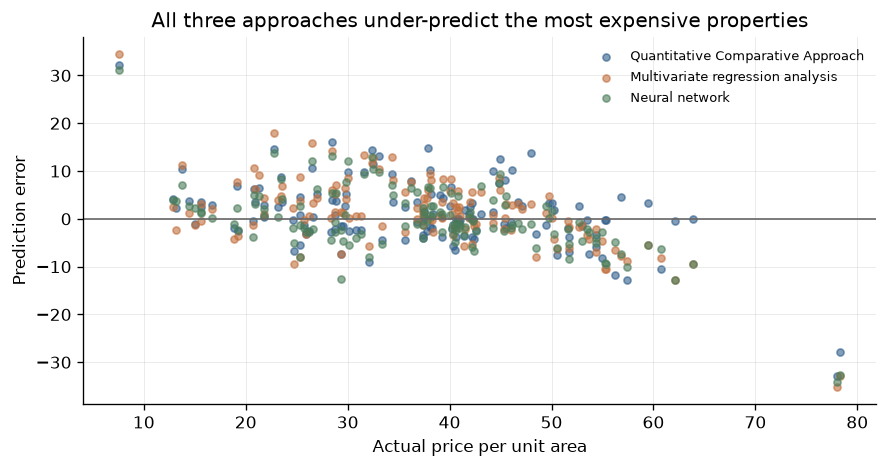

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for name in errors:
    ax.scatter(y_test, errors[name], s=18, alpha=0.6,
               label=name.replace(" (paper spec)", ""))
ax.axhline(0, color="0.4", lw=1)
ax.set_xlabel("Actual price per unit area")
ax.set_ylabel("Prediction error")
ax.set_title("All three approaches under-predict the most expensive properties")
ax.legend(fontsize=8)
fig.tight_layout()

Every approach shrinks towards the middle of the price range, the standard behaviour of a model fitted on squared error with few observations in the tails. Neither the paper's method nor its benchmarks address it.